# Simple ISIS accelerator test

## Imports

In [13]:
from pathlib import Path
import numpy as np 
import matplotlib.pyplot as plt
import xobjects as xo
from sim_utils import build_line, add_monitor, add_spacecharge_xfields

## Parameters for the simulation

In [3]:
n_monitors = 20
n_turns = 50

## Build the line

In [2]:
line = build_line()

/home/robert/projects/indirect_space_charge_python/Lattice_Files/02_Aperture_Lattice/ISIS.injected_beam


Converting sequence "synchrotron": 100%|██████████| 1990/1990 [00:02<00:00, 863.71it/s] 


## Add particles

In [5]:
particles = line.build_particles(x=0, y=0, px=0, py=0)

## Add monitors

In [6]:
length = line.get_length()
for i, s in enumerate(np.linspace(0, length, n_monitors, endpoint=False)):
    line = add_monitor(line, particles, s, n_turns, name=i+1)

Slicing line: 100%|██████████| 4017/4017 [00:00<00:00, 351978.76it/s]


## Add spacecharge

In [8]:
n_spacecharge_elements = 20
line = add_spacecharge_xfields(line, 1e12, n_spacecharge_elements, nemitt_x=1e-6, nemitt_y=1e-6)

Slicing line: 100%|██████████| 4020/4020 [00:00<00:00, 408952.27it/s]


## Build and track

In [9]:
line.build_tracker(_context=xo.ContextCpu(omp_num_threads=10))
line.track(particles, num_turns=n_turns, time=True)

Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.


## Get monitor Output

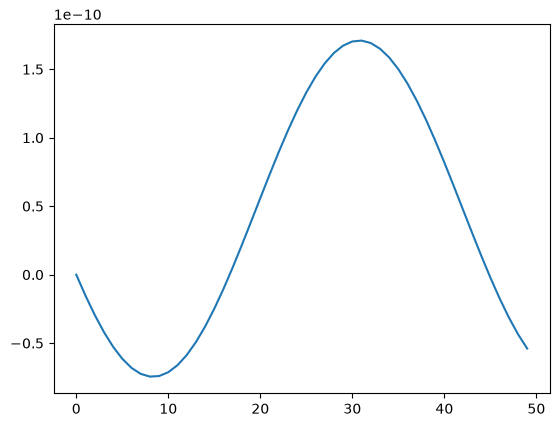

In [15]:
x = line.element_dict['monitor_1'].x.T

plt.plot(x)